# Задание 3.1

**(Задача о равномерном спуске)** Найти такую кривую, что тяжёлая точка под действием силы тяжести равномерно опускается по этой кривой. Условие задачи предполагает, что точка движется по кривой, расположенной в некоторой вертикальной плоскости.

1) В ноутбуке (файл Jupyter Notebook) в разметке Markdown (LaTeX) привести подробное аналитическое решение (составление дифференциального уравнения, его решение);
2) Привести статическую картинку в формате png (pdf) решения задачи (код на Jupyter Notebook, который создаёт рисунок);
3) Используя инструментарий Jupyter Notebook, привести анимацию данного решения.

**Детализация задания.** *Цель:* исследовать и визуализировать кривую, по которой материальная точка движется с постоянной вертикальной скоростью под действием силы тяжести.

- **Аналитическое решение:** ввести систему координат ($x$ — горизонталь, $y$ — вертикаль вверх); записать условие равномерного вертикального движения $v_y=\mathrm{const}<0$; составить дифференциальное уравнение из второго закона Ньютона; исключить силу нормальной реакции; проинтегрировать уравнение; найти явный вид кривой $y=f(x)$.
- **Статическая визуализация:** график кривой для различных начальных условий; отметить начальное положение точки; сетка, подписи осей, легенда; сохранить рисунок в png.
- **Анимация:** `FuncAnimation`; движение точки по кривой с постоянной вертикальной скоростью; динамическое отображение параметров движения; управление анимацией (пауза, воспроизведение).

## Теория

**1. Система координат и условие равномерного спуска.** Ось $x$ — горизонталь, ось $y$ — вертикаль вверх. Точка массы $m$ движется без трения по кривой в плоскости $Oxy$. Равномерный спуск означает, что вертикальная составляющая скорости постоянна:

$$
v_y=\dot y=-c=\mathrm{const}<0\quad\Longrightarrow\quad y(t)=y_0-ct,\qquad \ddot y=0 .
$$

**2. Второй закон Ньютона.** На точку действуют сила тяжести $m\vec g=(0,\,-mg)$ и нормальная реакция кривой $\vec N=(N_x,\,N_y)$:

$$
m\ddot x=N_x,\qquad m\ddot y=-mg+N_y .
$$

Так как $\ddot y=0$, получаем $N_y=mg$.

**3. Исключение нормальной реакции.** Реакция перпендикулярна кривой, то есть скорости: $\vec N\cdot\vec v=N_x\dot x+N_y\dot y=0$. Отсюда

$$
N_x=-N_y\,\frac{\dot y}{\dot x}=\frac{mgc}{\dot x}
\qquad\Longrightarrow\qquad
\boxed{\ \ddot x=\frac{gc}{\dot x}\ }\quad\Longleftrightarrow\quad \dot x\,\ddot x=gc .
$$

**4. Интегрирование.** Левая часть — полная производная: $\dfrac{d}{dt}\Big(\dfrac{\dot x^2}{2}\Big)=gc$, поэтому

$$
\dot x^2=\dot x_0^2+2gct=\dot x_0^2+2g\,(y_0-y).
$$

(Это закон сохранения энергии: $v^2=\dot x^2+c^2=v_0^2+2g(y_0-y)$.) Уравнение траектории:

$$
\frac{dy}{dx}=\frac{\dot y}{\dot x}=-\frac{c}{\sqrt{\dot x_0^2+2g\,(y_0-y)}} .
$$

Это уравнение с разделяющимися переменными. Введём глубину $u=y^*-y$ под уровнем $y^*=y_0+\dfrac{\dot x_0^2}{2g}$, на котором $\dot x=0$. Тогда $\dot x=\sqrt{2gu}$ и

$$
c\,dx=\sqrt{2g}\,u^{1/2}\,du\quad\Longrightarrow\quad x-x^*=\frac{2\sqrt{2g}}{3c}\,u^{3/2},
\qquad x^*=x_0-\frac{\dot x_0^{\,3}}{3gc}.
$$

**5. Явный вид кривой.** Выражая $u$ через $x$:

$$
\boxed{\ y=f(x)=y^*-\left(\frac{9c^2}{8g}\right)^{1/3}(x-x^*)^{2/3},\qquad x\ge x^*\ }
\qquad\Longleftrightarrow\qquad (y^*-y)^3=\frac{9c^2}{8g}\,(x-x^*)^2 .
$$

Это **полукубическая парабола** (изохрона Лейбница). Её вершина $(x^*,y^*)$ — точка возврата с вертикальной касательной: там $\dot x=0$, и точка движется строго вниз со скоростью $c$. Если точка стартует из вершины ($\dot x_0=0$), то $y=y_0-\left(\frac{9c^2}{8g}\right)^{1/3}(x-x_0)^{2/3}$. При разных начальных условиях кривые при одном и том же $c$ получаются сдвигом одной кривой; при росте $c$ кривая становится круче.

**6. Закон движения** (используется в анимации):

$$
y(t)=y_0-ct,\qquad u(t)=\frac{\dot x_0^2}{2g}+ct,\qquad x(t)=x^*+\frac{2\sqrt{2g}}{3c}\,u(t)^{3/2},\qquad \dot x(t)=\sqrt{2g\,u(t)} .
$$

Горизонтальная скорость растёт как $\sqrt t$, а вертикальная остаётся равной $-c$. Поэтому за равные промежутки времени точка опускается на одинаковую высоту.

**Проверка в коде.** Пускаем точку по найденной кривой, беря модуль скорости только из закона сохранения энергии, и проверяем, что вертикальная проекция скорости всюду равна $-c$.

**Анимация.** `FuncAnimation` встраивается в ноутбук через `to_jshtml()`. Получается проигрыватель с кнопками «пуск/пауза», пошаговой перемоткой и регулировкой скорости, который работает и в сохранённом ноутбуке.

c = 1.0, vx0 = 0.0:  max |v_y + c| = 4.4e-16
c = 2.0, vx0 = 1.5:  max |v_y + c| = 1.3e-15
c = 4.0, vx0 = 3.0:  max |v_y + c| = 1.8e-15


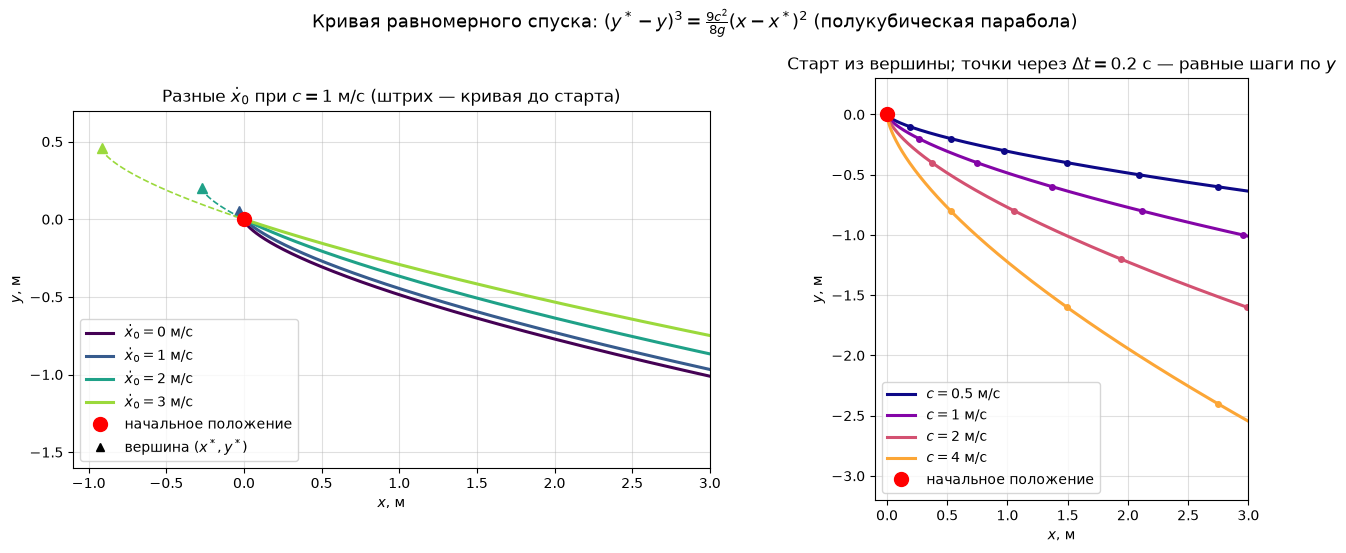

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

g = 9.81  # ускорение свободного падения, м/с²


def vertex(x0, y0, c, vx0):
    """Вершина (x*, y*) кривой для старта из (x0, y0) со скоростью (vx0, -c)."""
    return x0 - vx0**3 / (3*g*c), y0 + vx0**2 / (2*g)


def curve(x, xs, ys, c):
    """Найденная кривая: y = y* - (9c²/8g)^{1/3} (x - x*)^{2/3}."""
    return ys - (9*c**2 / (8*g))**(1/3) * np.abs(x - xs)**(2/3)


def curve_slope(x, xs, c):
    """Производная dy/dx = -(2/3)(9c²/8g)^{1/3} (x - x*)^{-1/3}."""
    return -(2/3) * (9*c**2 / (8*g))**(1/3) * (x - xs)**(-1/3)


def motion(t, x0, y0, c, vx0):
    """Закон движения: y = y0 - ct,  x = x* + (2√(2g)/3c)·u^{3/2},  u = vx0²/2g + ct."""
    xs, _ = vertex(x0, y0, c, vx0)
    u = vx0**2 / (2*g) + c*t
    return xs + 2*np.sqrt(2*g) / (3*c) * u**1.5, y0 - c*t, np.sqrt(2*g*u)


# ---------- Проверка: скорость из закона сохранения энергии даёт v_y ≡ -c ----------
for c, vx0 in [(1.0, 0.0), (2.0, 1.5), (4.0, 3.0)]:
    x0, y0 = 0.0, 0.0
    xs, ys = vertex(x0, y0, c, vx0)
    x = np.linspace(x0 + 1e-6, x0 + 3, 2001)
    y, k = curve(x, xs, ys, c), curve_slope(x, xs, c)
    v = np.sqrt(vx0**2 + c**2 + 2*g*(y0 - y))       # |v| из закона сохранения энергии
    vy = v * k / np.sqrt(1 + k**2)                   # проекция скорости на вертикаль (движение вправо)
    print(f"c = {c}, vx0 = {vx0}:  max |v_y + c| = {np.max(np.abs(vy + c)):.1e}")

# ---------- Статический рисунок ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# (а) одна скорость спуска c, разные начальные горизонтальные скорости vx0
ax = axes[0]
c = 1.0
for vx0, col in zip([0.0, 1.0, 2.0, 3.0], plt.cm.viridis(np.linspace(0, 0.85, 4))):
    xs, ys = vertex(0, 0, c, vx0)
    xx = np.linspace(xs, 3, 600)
    yy = curve(xx, xs, ys, c)
    ax.plot(xx[xx >= 0], yy[xx >= 0], color=col, lw=2.2, label=rf"$\dot x_0={vx0:g}$ м/с")
    ax.plot(xx[xx <= 0], yy[xx <= 0], color=col, lw=1.2, ls="--")      # продолжение кривой до вершины
    ax.plot(xs, ys, "^", color=col, ms=7)                              # вершина (точка возврата)
ax.plot(0, 0, "o", color="red", ms=10, zorder=5, label="начальное положение")
ax.plot([], [], "k^", label="вершина $(x^*,y^*)$")
ax.set_title(r"Разные $\dot x_0$ при $c=1$ м/с (штрих — кривая до старта)")

# (б) старт из вершины, разные скорости спуска c; точки — положения через равные Δt
ax = axes[1]
dt = 0.2
for c, col in zip([0.5, 1.0, 2.0, 4.0], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    xx = np.linspace(0, 3, 600)
    ax.plot(xx, curve(xx, 0, 0, c), color=col, lw=2.2, label=f"$c={c:g}$ м/с")
    tk = np.arange(0, 10, dt)
    xk, yk, _ = motion(tk, 0, 0, c, 0)
    keep = xk <= 3
    ax.plot(xk[keep], yk[keep], "o", color=col, ms=4)
ax.plot(0, 0, "o", color="red", ms=10, zorder=5, label="начальное положение")
ax.set_title(rf"Старт из вершины; точки через $\Delta t={dt}$ с — равные шаги по $y$")

for ax in axes:
    ax.set_xlabel("$x$, м")
    ax.set_ylabel("$y$, м")
    ax.grid(alpha=0.4)
    ax.legend(loc="lower left")
    ax.set_aspect("equal")
axes[0].set_xlim(-1.1, 3); axes[0].set_ylim(-1.6, 0.7)
axes[1].set_xlim(-0.1, 3); axes[1].set_ylim(-3.2, 0.3)
fig.suptitle(r"Кривая равномерного спуска: $(y^*-y)^3=\frac{9c^2}{8g}(x-x^*)^2$ (полукубическая парабола)", fontsize=13)
fig.tight_layout()
fig.savefig("3.1.png", dpi=150)          # сохраняем статическую картинку
plt.show()

# ---------- Анимация ----------
c, vx0, x0, y0 = 3.0, 0.0, 0.0, 0.0      # спуск со скоростью 3 м/с из вершины
T, n_frames = 1.0, 90
t_frames = np.linspace(0, T, n_frames)
X, Y, VX = motion(t_frames, x0, y0, c, vx0)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), dpi=72, gridspec_kw=dict(width_ratios=[1.5, 1]))
xx = np.linspace(0, X[-1], 400)
ax.plot(xx, curve(xx, *vertex(x0, y0, c, vx0), c), "k-", lw=1.5, label="кривая $y=f(x)$")
for yk in y0 - c*np.arange(0, T + 1e-9, 0.1):          # уровни, проходимые через каждые 0.1 с
    ax.axhline(yk, color="gray", lw=0.6, ls=":")
ax.plot(x0, y0, "o", color="red", ms=8, label="начальное положение")
trail, = ax.plot([], [], color="tab:blue", lw=3, alpha=0.5)
point, = ax.plot([], [], "o", color="tab:blue", ms=12, label="точка")
arrow = ax.quiver([x0], [y0], [0], [0], angles="xy", scale_units="xy", scale=4, color="tab:green", width=0.006)
info = ax.text(0.55, 0.95, "", transform=ax.transAxes, va="top", family="monospace",
               bbox=dict(boxstyle="round", fc="white", alpha=0.9))
ax.set(xlim=(-0.3, X[-1] + 0.3), ylim=(Y[-1] - 0.3, 0.4), xlabel="$x$, м", ylabel="$y$, м", aspect="equal",
       title="Движение точки (пунктир — уровни через каждые 0.1 с)")
ax.grid(alpha=0.3); ax.legend(loc="lower left")

# правая панель: компоненты скорости во времени
ax2.set(xlim=(0, T), ylim=(-c - 1, VX.max() + 1), xlabel="$t$, с", ylabel="скорость, м/с", title="Скорости")
ax2.axhline(0, color="k", lw=0.8); ax2.grid(alpha=0.3)
l_vx, = ax2.plot([], [], lw=2, label=r"$v_x=\sqrt{2gct}$")
l_vy, = ax2.plot([], [], lw=2, label=r"$v_y=-c$ (const)")
l_v, = ax2.plot([], [], lw=2, ls="--", label=r"$|v|$")
ax2.legend(loc="center right")


def update(i):
    t = t_frames[i]
    trail.set_data(X[:i+1], Y[:i+1])
    point.set_data([X[i]], [Y[i]])
    arrow.set_offsets([[X[i], Y[i]]])
    arrow.set_UVC([VX[i]], [-c])                    # вектор скорости (vx, -c)
    v = np.hypot(VX[:i+1], c)
    l_vx.set_data(t_frames[:i+1], VX[:i+1])
    l_vy.set_data(t_frames[:i+1], -c*np.ones(i+1))
    l_v.set_data(t_frames[:i+1], v)
    # динамическое отображение параметров движения
    info.set_text(f"t   = {t:5.2f} с\nx   = {X[i]:5.2f} м\ny   = {Y[i]:5.2f} м\n"
                  f"v_x = {VX[i]:5.2f} м/с\nv_y = {-c:5.2f} м/с\n|v| = {v[-1]:5.2f} м/с")
    return trail, point, arrow, info, l_vx, l_vy, l_v


anim = FuncAnimation(fig, update, frames=n_frames, interval=40, blit=True)
fig.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml(default_mode="once")))   # проигрыватель: пуск/пауза, шаг, скорость